In [1]:
import numpy as np
import pandas as pd

import geopandas as gpd
from shapely.geometry import Point, Polygon
import pycno

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.offsetbox import AnchoredText
from matplotlib import cm

import glob
from pathlib import Path
import pickle

import netCDF4 as nc

biome_dict = {'Boreal Forests/Taiga': 6,'Deserts & Xeric Shrublands': 13,'Flooded Grasslands & Savannas': 9,
            'Mediterranean Forests, Woodlands & Scrub': 12,'Montane Grasslands & Shrublands': 10,
            'Temperate Broadleaf & Mixed Forests': 4,'Temperate Conifer Forests': 5,
            'Temperate Grasslands, Savannas & Shrublands': 8,'Tropical & Subtropical Coniferous Forests': 3,
            'Tropical & Subtropical Dry Broadleaf Forests': 2,'Tropical & Subtropical Grasslands, Savannas & Shrublands': 7,
            'Tropical & Subtropical Moist Broadleaf Forests': 1,'Tundra': 11,'Lake': 98,'Rock/Ice': 99,'Mangrove': 14}
biome_dict = {v: k for k, v in biome_dict.items()}

tab10 = cm.get_cmap("tab10").colors
tab20b = cm.get_cmap("tab20b").colors
tab20c = cm.get_cmap("tab20c").colors
tab20 = cm.get_cmap("tab20").colors
Set2 = cm.get_cmap("Set2").colors
Dark2 = cm.get_cmap("Dark2").colors
Paired = cm.get_cmap("Paired").colors

biome_colors = {'Boreal Forests/Taiga':tab20[1],'Tundra':tab20c[17],'Deserts & Xeric Shrublands':tab20b[10],
               'Mediterranean Forests, Woodlands & Scrub':tab20b[8],'Montane Grasslands & Shrublands':Set2[5],
               'Flooded Grasslands & Savannas':tab20[5],'Temperate Grasslands, Savannas & Shrublands':Set2[4],
               'Tropical & Subtropical Grasslands, Savannas & Shrublands':tab20[17],
               'Temperate Broadleaf & Mixed Forests':(0.2,0.4,0),'Tropical & Subtropical Moist Broadleaf Forests':tab20[4],
               'Tropical & Subtropical Dry Broadleaf Forests':tab20[16],'Temperate Conifer Forests':Paired[11],
                'Tropical & Subtropical Coniferous Forests':tab20b[5],'Mangrove':[0.27,0.28,0.02],'Lake':[0,0,1],
                'Rock/Ice':[1,1,1]}

In [2]:
# df = pd.read_csv('Rx_Master/Rx_MASTER_v2024-05-29.csv',low_memory=False)

In [2]:
df = pd.read_csv('Rx_Master/US_master.csv',low_memory=False)

<AxesSubplot:>

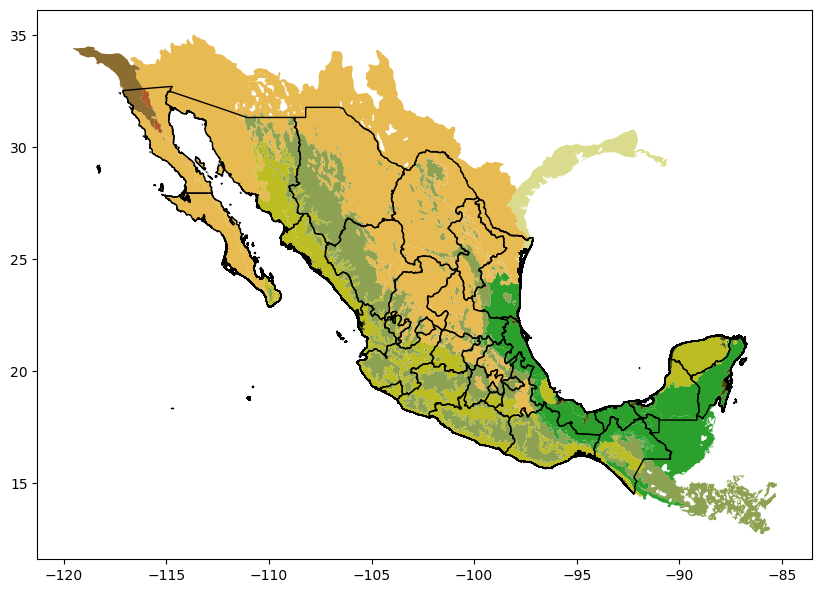

In [108]:
country='Mexico'
try:
    country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).to_crs('EPSG:4326')
except:
    # If shapefile doesn't have a pre-existing CRS
    country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).set_crs('EPSG:4326')
country_shp.set_index(country_shp.columns[0],inplace=True)
bounds = country_shp['geometry'].bounds

# Ecoregions shapefile
eco_shp = gpd.read_file('official_teow/wwf_terr_ecos.shp').to_crs('EPSG:4326')
eco_shp.set_index('OBJECTID',inplace=True)

# Find ecoregions only within country
country_eco_shp = gpd.sjoin(country_shp,eco_shp)

# Index of ecoregions in country in original ecoregion shapefile
eco_idx = np.unique(country_eco_shp['index_right'])

# Extract ecoregions only within country
country_eco = eco_shp.loc[eco_idx]

country_eco['Biome (Olson)'] = country_eco['BIOME'].astype(int).map(biome_dict).values

fig, ax = plt.subplots(figsize=(10,10))
# ax.set_xlim(xlim)
# ax.set_ylim(ylim)
# cno = pycno.cno()
# cno.draw('MWDB_Coasts_Countries_1.cnob')
country_eco.plot(color=country_eco['Biome (Olson)'].map(biome_colors),ax=ax,categories=biome_dict.values(),aspect='equal')
country_shp.plot(facecolor='none',edgecolor='black',ax=ax)

In [21]:
def ecoinfo(lon,lat):
    biome_dict = {'Boreal Forests/Taiga': 6,'Deserts & Xeric Shrublands': 13,'Flooded Grasslands & Savannas': 9,
            'Mediterranean Forests, Woodlands & Scrub': 12,'Montane Grasslands & Shrublands': 10,
            'Temperate Broadleaf & Mixed Forests': 4,'Temperate Conifer Forests': 5,
            'Temperate Grasslands, Savannas & Shrublands': 8,'Tropical & Subtropical Coniferous Forests': 3,
            'Tropical & Subtropical Dry Broadleaf Forests': 2,'Tropical & Subtropical Grasslands, Savannas & Shrublands': 7,
            'Tropical & Subtropical Moist Broadleaf Forests': 1,'Tundra': 11,'Lake': 98,'Rock/Ice': 99,'Mangrove': 14}
    biome_dict = {v: k for k, v in biome_dict.items()}

    eco_shp = gpd.read_file('../wwf_ecoregions/wwf_terr_ecos.shp')
    eco_shp.drop(eco_shp.columns[0],axis='columns',inplace=True)

    fire_pts = gpd.GeoDataFrame({'geometry':[Point(xy) for xy in zip([lon],[lat])]})
    fire_pts.crs = 'EPSG:4326'
    
    eco_join = gpd.sjoin(fire_pts,eco_shp)
    
    return eco_join['ECO_NAME'], eco_join['BIOME'].astype(int).map(biome_dict)

## Add Biome and Ecoregions

In [4]:
eco_shp = gpd.read_file('../wwf_ecoregions/wwf_terr_ecos.shp')
eco_shp.drop(eco_shp.columns[0],axis='columns',inplace=True)

fire_pts = gpd.GeoDataFrame({'geometry':[Point(xy) for xy in zip(df['Longitude'],df['Latitude'])]})
fire_pts.crs = 'EPSG:4326'

eco_join = gpd.sjoin(fire_pts,eco_shp)
df['Ecoregion (Olson)'] = np.nan
df.loc[eco_join.index,'Ecoregion (Olson)'] = eco_join['ECO_NAME']

df['Biome (Olson)'] = np.nan 
df.loc[eco_join.index,'Biome (Olson)'] = eco_join['BIOME'].astype(int).map(biome_dict)

# df.to_csv('Rx_Master/Rx_MASTER_v2024-05-13.csv',index=False)
df.to_csv('Rx_Master/US_master.csv',index=False)

## Add WDPA Areas

In [5]:
PA_df0 = gpd.read_file('../WDPA_May2024_Public_shp/WDPA_shp_0/WDPA_May2024_Public_shp-polygons.shp')
PA_df0 = PA_df0.loc[PA_df0['MARINE']!='2',['NAME','DESIG_ENG','GOV_TYPE','OWN_TYPE','IUCN_CAT','geometry']]

PA_df1 = gpd.read_file('../WDPA_May2024_Public_shp/WDPA_shp_1/WDPA_May2024_Public_shp-polygons.shp')
PA_df1 = PA_df1.loc[PA_df1['MARINE']!='2',['NAME','DESIG_ENG','GOV_TYPE','OWN_TYPE','IUCN_CAT','geometry']]

PA_df2 = gpd.read_file('../WDPA_May2024_Public_shp/WDPA_shp_2/WDPA_May2024_Public_shp-polygons.shp')
PA_df2 = PA_df2.loc[PA_df2['MARINE']!='2']

In [6]:
df['WDPA Name'] = np.nan
df['WDPA Governance'] = np.nan
df['WDPA Ownership'] = np.nan
df['WDPA Designation'] = np.nan
df['WDPA IUCN Category'] = np.nan

fire_pts = gpd.GeoDataFrame({'geometry':[Point(xy) for xy in zip(df['Longitude'],df['Latitude'])]})
fire_pts.crs = 'EPSG:4326'

In [7]:
PA0_join = gpd.sjoin(fire_pts,PA_df0)
PA1_join = gpd.sjoin(fire_pts,PA_df1)
PA2_join = gpd.sjoin(fire_pts,PA_df2)

In [8]:
df.loc[PA0_join.index,'WDPA Name'] = PA0_join['NAME'].values
df.loc[PA0_join.index,'WDPA Governance'] = PA0_join['GOV_TYPE'].values
df.loc[PA0_join.index,'WDPA Ownership'] = PA0_join['OWN_TYPE'].values
df.loc[PA0_join.index,'WDPA Designation'] = PA0_join['DESIG_ENG'].values
df.loc[PA0_join.index,'WDPA IUCN Category'] = PA0_join['IUCN_CAT'].values

df.loc[PA1_join.index,'WDPA Name'] = PA1_join['NAME']
df.loc[PA1_join.index,'WDPA Governance'] = PA1_join['GOV_TYPE']
df.loc[PA1_join.index,'WDPA Ownership'] = PA1_join['OWN_TYPE']
df.loc[PA1_join.index,'WDPA Designation'] = PA1_join['DESIG_ENG']
df.loc[PA1_join.index,'WDPA IUCN Category'] = PA1_join['IUCN_CAT']

df.loc[PA2_join.index,'WDPA Name'] = PA2_join['NAME']
df.loc[PA2_join.index,'WDPA Governance'] = PA2_join['GOV_TYPE']
df.loc[PA2_join.index,'WDPA Ownership'] = PA2_join['OWN_TYPE']
df.loc[PA2_join.index,'WDPA Designation'] = PA2_join['DESIG_ENG']
df.loc[PA2_join.index,'WDPA IUCN Category'] = PA2_join['IUCN_CAT']

In [9]:
# df.to_csv('Rx_Master/Rx_MASTER_v2024-05-29.csv',index=False)
df.to_csv('Rx_Master/US_master.csv',index=False)

In [10]:
df

,ID,Latitude,Longitude,Year,Month,Day,Time,Country,State/Province,Agency/Organisation,...,datestring,Koppen Climate,Topography,Ecoregion (Olson),Biome (Olson),WDPA Name,WDPA Governance,WDPA Ownership,WDPA Designation,WDPA IUCN Category
0,Rx20171001-N65.9838-W152.0235,65.983791,-152.023523,2017,10.0,1.0,NaN,United States,Alaska,United States Geological Survey (USGS),...,20171001,27.0,359.0,Interior Yukon-Alaska alpine tundra,Tundra,NaN,NaN,NaN,NaN,NaN
1,Rx20150620-N65.9980-W141.1310,65.997981,-141.131003,2015,6.0,20.0,NaN,United States,Alaska,United States Geological Survey (USGS),...,20150620,27.0,467.0,Ogilvie-MacKenzie alpine tundra,Tundra,NaN,NaN,NaN,NaN,NaN
2,Rx20151001-N66.0248-W160.4426,66.024820,-160.442568,2015,10.0,1.0,NaN,United States,Alaska,United States Geological Survey (USGS),...,20151001,27.0,201.0,Beringia upland tundra,Tundra,NaN,NaN,NaN,NaN,NaN
3,Rx20191001-N66.0248-W160.4426,66.024820,-160.442568,2019,10.0,1.0,NaN,United States,Alaska,United States Geological Survey (USGS),...,20191001,27.0,201.0,Beringia upland tundra,Tundra,NaN,NaN,NaN,NaN,NaN
4,Rx20191001-N66.0565-W141.9083,66.056534,-141.908258,2019,10.0,1.0,NaN,United States,Alaska,United States Geological Survey (USGS),...,20191001,27.0,392.0,Interior Alaska-Yukon lowland taiga,Boreal Forests/Taiga,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42321,Rx20150205-N32.8534-W116.4381,32.853365,-116.438072,2015,2.0,5.0,NaN,USA,California,Fire and Tree Mortality Database (Coleman),...,20150205,9.0,1590.0,California coastal sage and chaparral,"Mediterranean Forests, Woodlands & Scrub",NaN,NaN,NaN,NaN,NaN
42322,Rx20160927-N46.8003-W121.0835,46.800265,-121.083470,2016,9.0,27.0,NaN,USA,Washington,Fire and Tree Mortality Database (FERA),...,20160927,18.0,1188.0,Eastern Cascades forests,Temperate Conifer Forests,NaN,NaN,NaN,NaN,NaN
42323,Rx20161004-N47.6746-W120.5385,47.674619,-120.538474,2016,10.0,4.0,NaN,USA,Washington,Fire and Tree Mortality Database (FERA),...,20161004,18.0,902.0,Cascade Mountains leeward forests,Temperate Conifer Forests,NaN,NaN,NaN,NaN,NaN
42324,Rx20160922-N47.3262-W120.6857,47.326231,-120.685703,2016,9.0,22.0,NaN,USA,Washington,Fire and Tree Mortality Database (FERA),...,20160922,18.0,1126.0,Cascade Mountains leeward forests,Temperate Conifer Forests,NaN,NaN,NaN,NaN,NaN
